In [17]:
# Run in conda ibiz environment
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import os

# Load preprocessing functions
from utils import load_L1B_radargram, get_l2_path_from_l1b, load_l2_ice_thickness, add_polarstereo_coordinates, merge_radargram_and_l1b, convert_radargram_to_elevations
from utils import generate_bed_idx_and_mask, crop_tiles_extract_metadata

# Load preprocessing configs
from preprocess_radargrams_configs import TX_OFFSET_EAGLE_HiCARS2_microseconds
# Load visulaisation configs
from preprocess_radargrams_configs import AMPLITUDE_VMIN, AMPLITUDE_VMAX, COLOR_MAP
# Load tile specs explicity for investigations
from preprocess_radargrams_configs import IMAGE_TILE_WIDTH, IMAGE_TILE_HEIGHT, X_SPACING

# EAGLE HiCARS2 - INPUTS
from paths import path_to_ER2HI1B_2016
from paths import path_to_ER2HI2_2016_ice_thickness
# EAGLE HiCARS2 - OUTPUTS
from paths import path_to_tiles_metadata_EAGLE_2016
from paths import path_to_tiles_tensor_EAGLE_2016

# EAGLE 2016

In [18]:
list_of_nc_files_EAGLE_HiCARS2_full_paths = sorted(
    os.path.join(path_to_ER2HI1B_2016, f)
    for f in os.listdir(path_to_ER2HI1B_2016)
    if f.endswith(".nc")
)

print(len(list_of_nc_files_EAGLE_HiCARS2_full_paths), "files found.")
print()
print("First file:", list_of_nc_files_EAGLE_HiCARS2_full_paths[0])

237 files found.

First file: /Users/kim.bente/Documents/ANT_QGIS/AADC-DATA/2016_AN_UTIG.ER2HI1B.tar/2016_AN_UTIG.ER2HI1B/ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000.nc


In [ ]:
# Store as list first, then convert to torch tensor and pandas dataframe after the loop
all_tiles, all_meta = [], []
skipped = []

n_granules = len(list_of_nc_files_EAGLE_HiCARS2_full_paths)

start_at = 0

for i, path_to_l1b_granule in enumerate(
    list_of_nc_files_EAGLE_HiCARS2_full_paths[start_at:], start = start_at):
    # Keep track of progress through radargrams
    print(f"Granule {i} / {n_granules}")
    
    # 1. Load radargram and crop if lat/lon are missing
    radargram_ds = load_L1B_radargram(path_to_l1b_granule)
    # Continue to next granule if, for instance, no valid lat/lon coordinates are found.
    if radargram_ds is None:
        print("------------------------------")
        continue

    # 2. Get the corresponding L2 file path
    path_to_l2_file = get_l2_path_from_l1b(radargram_ds.granule_id, path_to_ER2HI2_2016_ice_thickness)

    # 3. Load L2 data
    l2_df = load_l2_ice_thickness(path_to_l2_file)

    if l2_df is None:
        skipped.append((str(radargram_ds.granule_id), "no L2 file or no valid rows"))
        print("------------------------------")
        continue

    # 4. Add Antarctic Polar Stereographic coordinates to L2 dataframe
    l2_df = add_polarstereo_coordinates(l2_df)

    # 5. Add l2 data to l1b
    radargram_ds_l2 = merge_radargram_and_l1b(radargram_ds, l2_df) 

    # 6. Convert radargram to elevations (2D grid of absolute elevations above sea level, in meters)
    # NOTE: Input the correct TX_OFFSET for the radargram type (HiCARS 1 or HiCARS 2) to convert fasttime to TWTT correctly.
    elevations_m = convert_radargram_to_elevations(radargram_ds_l2, TX_OFFSET_EAGLE_HiCARS2_microseconds)

    # 7. Generate bed index and mask
    bed_idx, bed_mask = generate_bed_idx_and_mask(elevations_m, radargram_ds_l2)

    # 8. Crop tiles for one radargram 
    tiles_per_granule, metadata_per_granule = crop_tiles_extract_metadata(radargram_ds_l2, elevations_m, bed_idx)

    if tiles_per_granule is None:
        print("------------------------------")
        continue

    all_tiles.append(tiles_per_granule)
    all_meta.append(metadata_per_granule)

# after the loop, once all the data is collected
# list to numpy array and pandas dataframe
tiles_np = np.concatenate(all_tiles, axis = 0)
tiles_metadata = pd.concat(all_meta, ignore_index = True)
# make tensor  
tiles_tensor = torch.from_numpy(tiles_np).unsqueeze(1) 

print("tiles_tensor shape:", tiles_tensor.shape)
print("tiles_metadata shape:", tiles_metadata.shape)

print("Skipped", skipped)

Granule 0 / 237
Now processing Granule ID: ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000
L1B radargram shape (rows, columns): (3200, 456)
L2 shape (rows): 456
Matched: 456 / 456
------------------------------
Granule 1 / 237
Now processing Granule ID: ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000
L1B radargram shape (rows, columns): (3200, 1179)
INFO: L1B radargram has 12 columns with missing LON/LAT
INFO: Cropped 12 trailing columns with missing LON/LAT
L2 shape (rows): 1167
Matched: 1167 / 1167
INFO: Dropped 2 / 3 tiles without a valid bed pick
------------------------------
Granule 2 / 237
Now processing Granule ID: ER2HI1B_2017023_ICP8_JKB2r_F07T04a_000
L1B radargram shape (rows, columns): (3200, 1225)
INFO: L1B radargram has 11 columns with missing LON/LAT
INFO: Cropped 11 trailing columns with missing LON/LAT
L2 shape (rows): 1214
Matched: 1214 / 1214
INFO: Dropped 3 / 3 tiles without a valid bed pick
------------------------------
Granule 3 / 237
Now processing Granule ID: ER2HI1B_2017023_ICP

# Export tensor and metadata

In [6]:
print("tiles_tensor shape:", tiles_tensor.shape)
print("tiles_metadata shape:", tiles_metadata.shape)

torch.save(tiles_tensor, path_to_tiles_tensor_EAGLE_2016)
pd.DataFrame.to_csv(tiles_metadata, path_to_tiles_metadata_EAGLE_2016, index = False)

tiles_tensor shape: torch.Size([636, 1, 336, 336])
tiles_metadata shape: (636, 18)


## EAGLE 2016 preprocessing observations:
- Mainly training LON/LAT values missing, so we ix this by pruning.
- No valid matches for ER2HI1B_2017023_ICP8_JKB2r_F07T08a_000
- Many tile candidates have no valid bed pick.

## Visualise granule (radargram) with bed

Show granule idx 1 where 2/3 tiles were dropped.

Now processing Granule ID: ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000
L1B radargram shape (rows, columns): (3200, 1179)
INFO: L1B radargram has 12 columns with missing LON/LAT
INFO: Cropped 12 trailing columns with missing LON/LAT
L2 shape (rows): 1167
Matched: 1167 / 1167


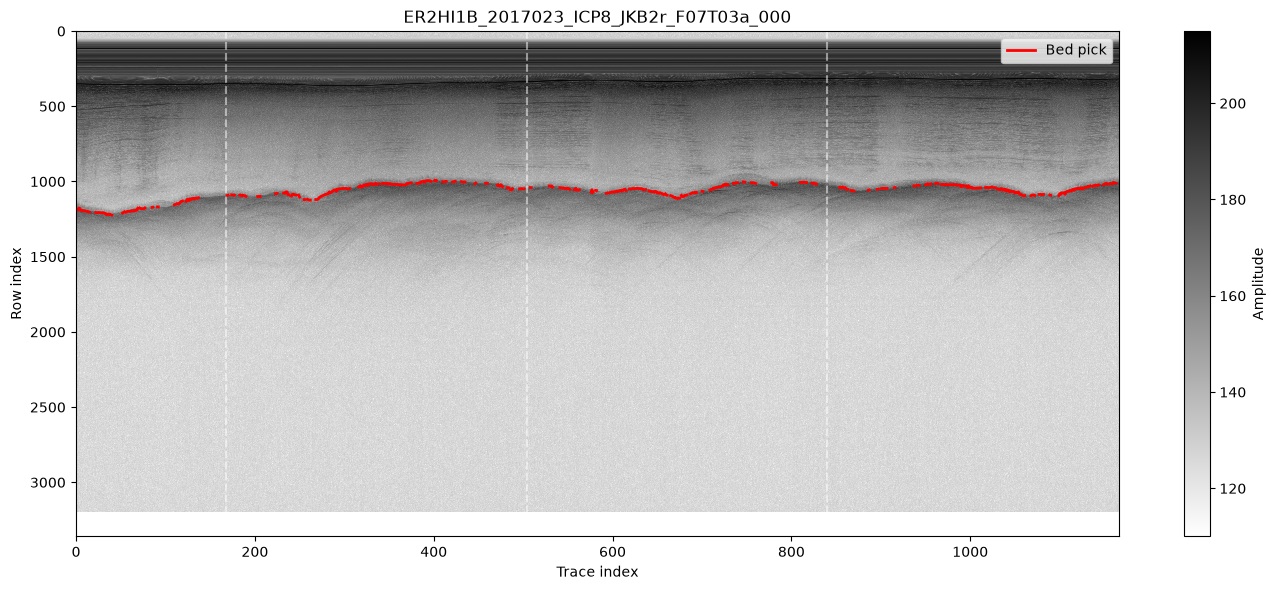

In [16]:
path_to_some_l1b_granule = list_of_nc_files_EAGLE_HiCARS2_full_paths[1]

# 1. Load radargram and crop if lat/lon are missing
radargram_ds = load_L1B_radargram(path_to_some_l1b_granule)

# 2. Get the corresponding L2 file path
path_to_l2_file = get_l2_path_from_l1b(radargram_ds.granule_id, path_to_ER2HI2_2016_ice_thickness)

# 3. Load L2 data
l2_df = load_l2_ice_thickness(path_to_l2_file)

# 4. Add Antarctic Polar Stereographic coordinates to L2 dataframe
l2_df = add_polarstereo_coordinates(l2_df)

# 5. Add l2 data to l1b
radargram_ds_l2 = merge_radargram_and_l1b(radargram_ds, l2_df) 

# 6. Convert radargram to elevations (2D grid of absolute elevations above sea level, in meters)
# NOTE: Input the correct TX_OFFSET for the radargram type (HiCARS 1 or HiCARS 2) to convert fasttime to TWTT correctly.
elevations_m = convert_radargram_to_elevations(radargram_ds_l2, TX_OFFSET_EAGLE_HiCARS2_microseconds)

# 7. Generate bed index and mask
bed_idx, bed_mask = generate_bed_idx_and_mask(elevations_m, radargram_ds_l2)

### VISUALIZE ONE RADARGRAM WITH BED PICK AND TILE LINES
amplitude = radargram_ds_l2["amplitude_high_gain"].values.T
n_rows, n_cols = amplitude.shape

# Calc where the x_centres or lines are
tile_x_centers = np.arange(IMAGE_TILE_WIDTH // 2, n_cols - IMAGE_TILE_WIDTH // 2, IMAGE_TILE_WIDTH)

trace_idx = np.arange(n_cols)
row_idx = np.arange(n_rows)

fig, ax = plt.subplots(figsize = (14, 6))
mesh = ax.pcolormesh(trace_idx, row_idx, amplitude, cmap = COLOR_MAP, vmin = AMPLITUDE_VMIN, vmax = AMPLITUDE_VMAX)
ax.plot(trace_idx, bed_idx, color = "red", linewidth = 2, label = "Bed pick")
ax.vlines(tile_x_centers, 0, n_rows, colors = "white", linestyles = "dashed", alpha = 0.5)
ax.invert_yaxis()                   
ax.set_xlabel("Trace index")
ax.set_ylabel("Row index")
ax.set_title(f"{radargram_ds_l2.granule_id}")
fig.colorbar(mesh, ax = ax, label = "Amplitude")
ax.legend(loc = "upper right")
plt.tight_layout()
plt.show()

Now processing Granule ID: ER2HI1B_2017023_ICP8_JKB2r_F07T08a_000
L1B radargram shape (rows, columns): (3200, 2108)
INFO: L1B radargram has 11 columns with missing LON/LAT
INFO: Cropped 11 trailing columns with missing LON/LAT
L2 shape (rows): 2097
Matched: 0 / 2097
The first dolumns of L2 (year) is treated as an index, which causes the issue.
[-67.62391 -67.62393 -67.62396 ... -67.76864 -67.76845 -67.76826]
[1512.88 1512.78 1512.69 ... 1502.05 1501.89 1501.74]


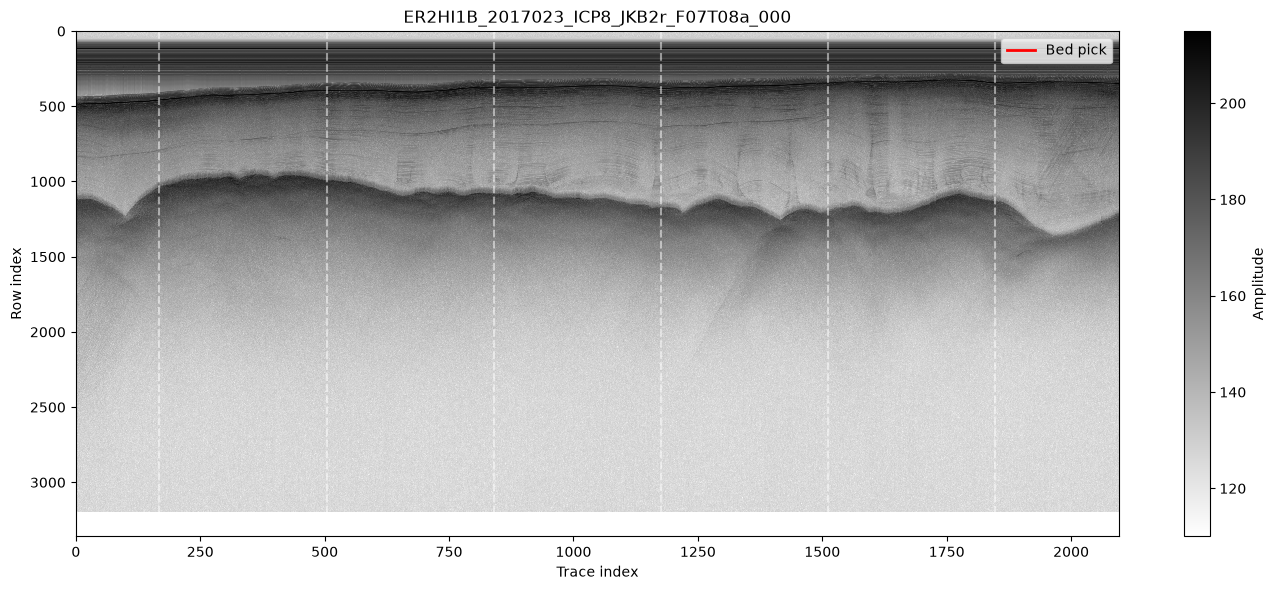

In [15]:
path_to_some_l1b_granule = list_of_nc_files_EAGLE_HiCARS2_full_paths[6]

# 1. Load radargram and crop if lat/lon are missing
radargram_ds = load_L1B_radargram(path_to_some_l1b_granule)

# 2. Get the corresponding L2 file path
path_to_l2_file = get_l2_path_from_l1b(radargram_ds.granule_id, path_to_ER2HI2_2016_ice_thickness)

# 3. Load L2 data
l2_df = load_l2_ice_thickness(path_to_l2_file)

# 4. Add Antarctic Polar Stereographic coordinates to L2 dataframe
l2_df = add_polarstereo_coordinates(l2_df)

# 5. Add l2 data to l1b
radargram_ds_l2 = merge_radargram_and_l1b(radargram_ds, l2_df) 

print("The first dolumns of L2 (year) is treated as an index, which causes the issue.")
print(radargram_ds_l2.lat.values)
print(l2_df.LAT.values)

# 6. Convert radargram to elevations (2D grid of absolute elevations above sea level, in meters)
# NOTE: Input the correct TX_OFFSET for the radargram type (HiCARS 1 or HiCARS 2) to convert fasttime to TWTT correctly.
elevations_m = convert_radargram_to_elevations(radargram_ds_l2, TX_OFFSET_EAGLE_HiCARS2_microseconds)

# 7. Generate bed index and mask
bed_idx, bed_mask = generate_bed_idx_and_mask(elevations_m, radargram_ds_l2)

### VISUALIZE ONE RADARGRAM WITH BED PICK AND TILE LINES
amplitude = radargram_ds_l2["amplitude_high_gain"].values.T
n_rows, n_cols = amplitude.shape

# Calc where the x_centres or lines are
tile_x_centers = np.arange(IMAGE_TILE_WIDTH // 2, n_cols - IMAGE_TILE_WIDTH // 2, IMAGE_TILE_WIDTH)

trace_idx = np.arange(n_cols)
row_idx = np.arange(n_rows)

fig, ax = plt.subplots(figsize = (14, 6))
mesh = ax.pcolormesh(trace_idx, row_idx, amplitude, cmap = COLOR_MAP, vmin = AMPLITUDE_VMIN, vmax = AMPLITUDE_VMAX)
ax.plot(trace_idx, bed_idx, color = "red", linewidth = 2, label = "Bed pick")
ax.vlines(tile_x_centers, 0, n_rows, colors = "white", linestyles = "dashed", alpha = 0.5)
ax.invert_yaxis()                   
ax.set_xlabel("Trace index")
ax.set_ylabel("Row index")
ax.set_title(f"{radargram_ds_l2.granule_id}")
fig.colorbar(mesh, ax = ax, label = "Amplitude")
ax.legend(loc = "upper right")
plt.tight_layout()
plt.show()

## Inspect min ice thickness

In [11]:
tiles_metadata.iloc[np.argmin(tiles_metadata["ice_thickness"])][["granule_id", "ice_thickness"]]

granule_id       ER2HI1B_2017034_DEN_JKB2r_Y44b_000
ice_thickness                                307.11
Name: 627, dtype: object

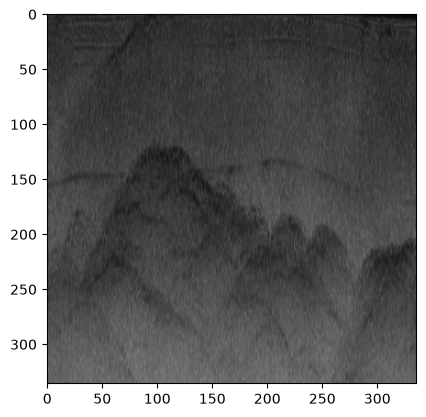

In [ ]:
# Show tile with min ice thickness
tiles_tensor[np.argmin(tiles_metadata["ice_thickness"]), : , :]
plt.imshow(tiles_tensor[np.argmin(tiles_metadata["ice_thickness"]), 0, :, :], vmin = AMPLITUDE_VMIN, vmax = AMPLITUDE_VMAX, cmap = COLOR_MAP)

# Plot some tiles

Saved 12 tiles to /Users/kim.bente/Code/RadarCLIP/figures/EAGLE_2016


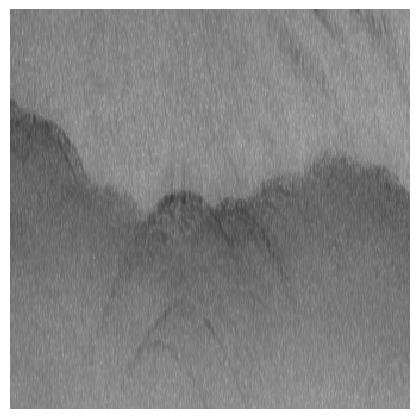

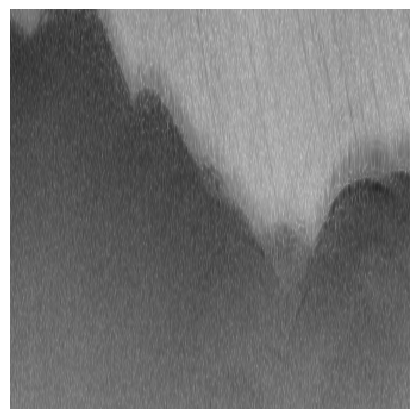

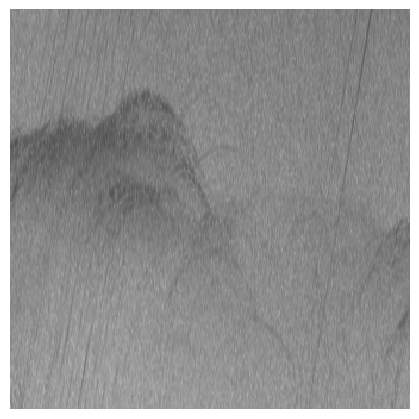

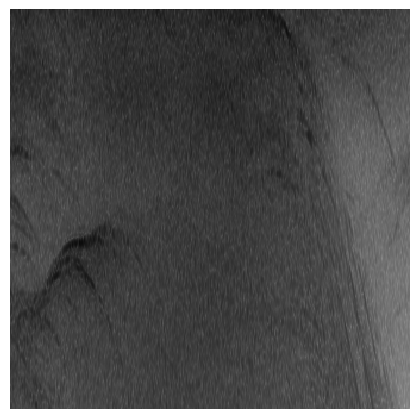

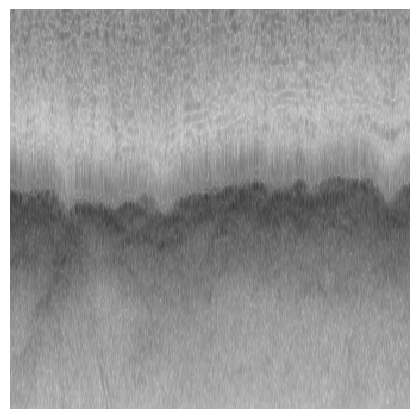

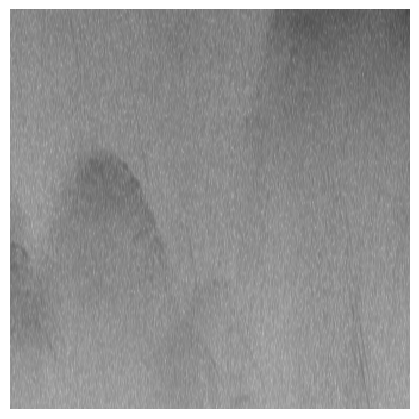

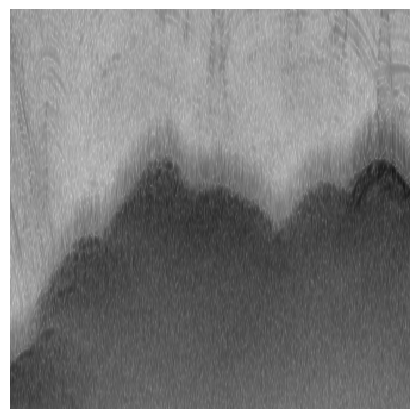

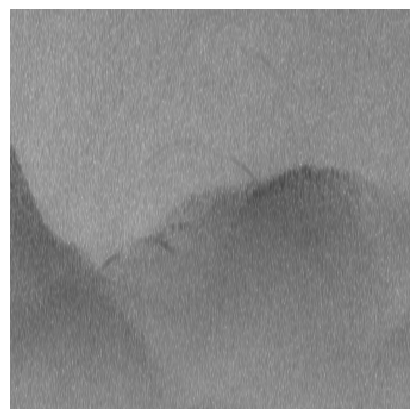

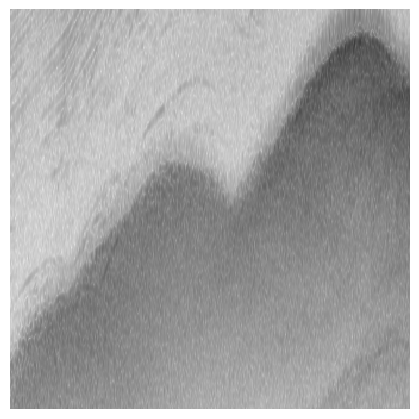

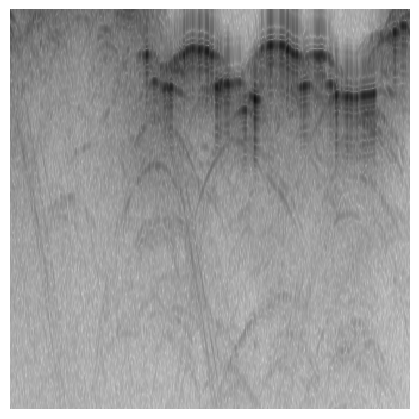

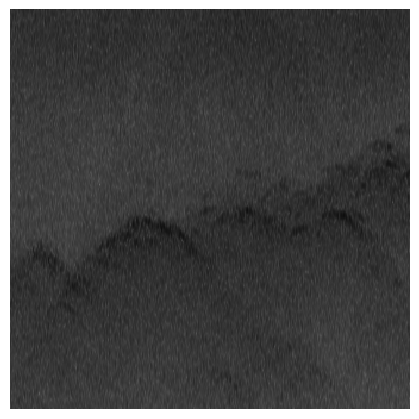

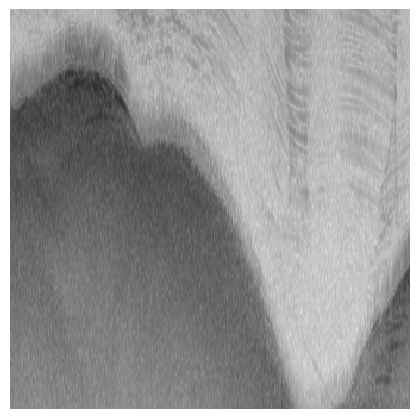

In [ ]:
figures_dir = "figures/EAGLE_2016_HiCARS2"

rng = np.random.default_rng(42)
idx = rng.choice(len(tiles_tensor), size = 12, replace = False)

for i in idx:
    # (C, H, W) -> (H, W); same channel mean as in your earlier plots
    tile = tiles_tensor[i].mean(dim = 0).cpu().numpy()
    h, w = tile.shape

    # figure sized to the tile's aspect ratio, axes fill the whole canvas
    fig = plt.figure(figsize = (w / h * 4, 4))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.pcolormesh(tile, cmap = COLOR_MAP, vmin = AMPLITUDE_VMIN, vmax = AMPLITUDE_VMAX)
    ax.invert_yaxis()      
    ax.set_axis_off()

    fig.savefig(os.path.join(figures_dir, f"tile_{i:06d}.png"), dpi = 300, bbox_inches = "tight", pad_inches = 0)

print(f"Saved {len(idx)} tiles to {os.path.abspath(figures_dir)}")